# Detección de Spam en Mensajes: Proceso de Ciencia de Datos

**Proyecto del curso:** Ciberataques y Ciencia de Datos para Defensa

**Integrantes del grupo:**

| Integrante |
|---|
| Fredy Alvarez |
| Sebastian Orozco |
| Cristian Yepes |
| Yenny Villarreal |

---

En este documento el equipo describe paso a paso la metodología aplicada
para construir un sistema de detección de spam sobre mensajes SMS. El
desarrollo combina dos enfoques complementarios:

1. **Modelado supervisado clásico**, entrenado por el equipo sobre el
   conjunto de datos SMS Spam Collection (carpeta `data/` del
   repositorio).
2. **Aprendizaje por transferencia**, mediante el modelo preentrenado
   [`Goodmotion/spam-mail-classifier`](https://huggingface.co/Goodmotion/spam-mail-classifier)
   publicado en Hugging Face, requisito del taller.

Ambos enfoques se evalúan sobre la misma partición de prueba, de modo que
la comparación entre ellos sea justa. El resultado de la evaluación y la
discusión final sustentan la decisión de integrar el modelo preentrenado
en la aplicación web del proyecto (carpeta `app/`).


## 1. Introducción y metodología

### 1.1 Contexto del problema

El spam es una de las formas más antiguas y persistentes de abuso en los
canales de comunicación digital. En el caso de los SMS, además de la
molestia para el usuario, estos mensajes frecuentemente actúan como
vector de ingeniería social: enlaces maliciosos, estafas de premios,
suplantación de instituciones financieras o cargos encubiertos por
suscripción. Un filtro automático que detecte el spam a partir del
contenido del mensaje es, por lo tanto, una medida de defensa directa.

El problema se plantea como **clasificación binaria de texto**: dada una
secuencia de caracteres que representa un mensaje, asignarle la etiqueta
`spam` (clase positiva, 1) o `ham` (mensaje legítimo, clase negativa, 0).

### 1.2 Fuentes de datos y herramientas

| Recurso | Descripción |
|---|---|
| Datos | SMS Spam Collection v.1: 5574 mensajes SMS en inglés etiquetados como `ham` o `spam`, archivo `data/SMSSpamCollection` |
| Modelo preentrenado | `Goodmotion/spam-mail-classifier` (Hugging Face), codificador Multilingual-MiniLM ajustado para clasificación binaria de spam |
| Librerías | `pandas` y `numpy` (manipulación de datos), `scikit-learn` (modelado y métricas), `transformers` y `torch` (modelo preentrenado), `matplotlib` (visualización) |

### 1.3 Metodología

El equipo organizó el trabajo siguiendo las fases típicas del ciclo de un
proyecto de ciencia de datos (en línea con las metodologías KDD y
CRISP-DM):

1. **Comprensión del problema y de los datos**: revisión del formato del
   conjunto de datos y definición de la clase positiva.
2. **Análisis exploratorio (EDA)**: balance de clases, longitudes de los
   mensajes y vocabulario característico de cada clase.
3. **Preprocesamiento y partición**: normalización mínima del texto y
   separación estratificada entrenamiento/prueba.
4. **Modelamiento y evaluación**: entrenamiento de clasificadores naïve
   Bayes y regresión logística sobre representaciones TF-IDF, seguido de
   la evaluación del modelo preentrenado sobre la misma partición.
5. **Comparación y conclusiones**: métricas, matrices de confusión,
   ejemplos de errores y discusión de limitaciones.

Todas las decisiones metodológicas se justifican en el texto de cada
sección, para que este notebook sirva también como material de estudio
para los demás compañeros del curso.


## 2. Configuración del entorno

En esta sección se importan las librerías y se fijan las semillas
aleatorias. La reproducibilidad es una decisión deliberada del equipo: el
conjunto de prueba debe ser idéntico en todas las ejecuciones del
notebook, de manera que las métricas que se reportan sean comparables.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import transformers
import torch

from pathlib import Path
from transformers import pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

# Semillas para reproducibilidad total del experimento.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"numpy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"transformers: {transformers.__version__}")
print(f"torch       : {torch.__version__}")
print(f"dispositivo : {'GPU' if torch.cuda.is_available() else 'CPU'}")


numpy       : 2.4.6
pandas      : 3.1.1
scikit-learn: 1.9.1
transformers: 5.22.2
torch       : 2.15.0+cpu
dispositivo : CPU


## 3. Carga y comprensión del conjunto de datos

El archivo SMS Spam Collection contiene un mensaje por línea, con la
etiqueta separada del texto por un carácter de tabulación. La etiqueta
`ham` corresponde a mensajes legítimos y `spam` a mensajes no deseados.
Desde este punto, el equipo trata `spam` como la **clase positiva (1)** y
`ham` como la clase negativa (0); esta convención se conserva en todas
las métricas del notebook.


In [2]:
DATA_PATH = Path("../data/SMSSpamCollection")

df = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "text"])

print(f"Mensajes: {len(df)}")
print(f"Columnas: {list(df.columns)}")
df.head(10)


Mensajes: 5572
Columnas: ['label', 'text']


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [3]:
# Revisión general: tipos de dato, valores nulos y duplicados exactos.
print(df.info())
print(f"\nValores nulos: {df.isna().sum().sum()}")
print(f"Duplicados exactos: {df.duplicated().sum()}")
print(f"\nEjemplo de spam:")
list(df.loc[df["label"] == "spam", "text"].head(3))


<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5572 non-null   str  
 1   text    5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None

Valores nulos: 0
Duplicados exactos: 403

Ejemplo de spam:


["Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's",
 "FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv",
 'WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.']

## 4. Análisis exploratorio de datos (EDA)

### 4.1 Balance de clases

El primer análisis cuantifica el equilibrio entre las clases, pues
condiciona la elección de las métricas de evaluación.


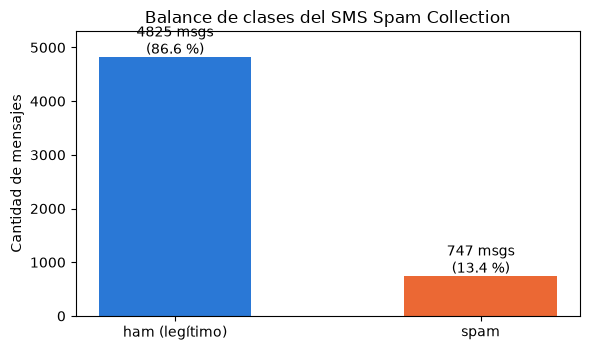

In [4]:
counts = df["label"].value_counts()
props = df["label"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(["ham (legítimo)", "spam"], counts.values,
              color=["#2a78d6", "#eb6834"], width=0.5)
for bar, n, p in zip(bars, counts.values, props.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 60,
            f"{n} msgs\n({p:.1f} %)", ha="center", fontsize=10)
ax.set_ylabel("Cantidad de mensajes")
ax.set_title("Balance de clases del SMS Spam Collection")
ax.set_ylim(0, 5300)
plt.tight_layout()
plt.show()


**Interpretación del equipo.** El conjunto está claramente desbalanceado:
el 86,6 % de los mensajes son legítimos y solo un 13,4 % son spam. Esta
proporción tiene dos consecuencias directas sobre el diseño del
experimento:

- **La exactitud (accuracy) es una métrica engañosa en este escenario.**
  Un clasificador trivial que etiquetara todo como `ham` alcanzaría un
  86,6 % de exactitud sin detectar ningún spam. Por eso el equipo prioriza
  la **precisión**, el **recall (exhaustividad)** y el **F1-score**
  calculados sobre la clase spam.
- La partición entrenamiento/prueba se hace de manera **estratificada**,
  para preservar en ambas particiones la proporción original de spam.

Sobre los 403 duplicados exactos, el equipo decide conservarlos: en el
dominio del spam los mensajes repetidos son un fenómeno natural (una
campaña envía el mismo texto a miles de números) y su repetición es en
sí misma un patrón de interés para el clasificador.


### 4.2 Longitud de los mensajes

Una hipótesis razonable es que los mensajes de spam tienden a ser más
largos que los legítimos, pues deben convencer al receptor de una oferta
o incluir instrucciones de contacto. La siguiente gráfica contrasta la
distribución de longitudes por clase.


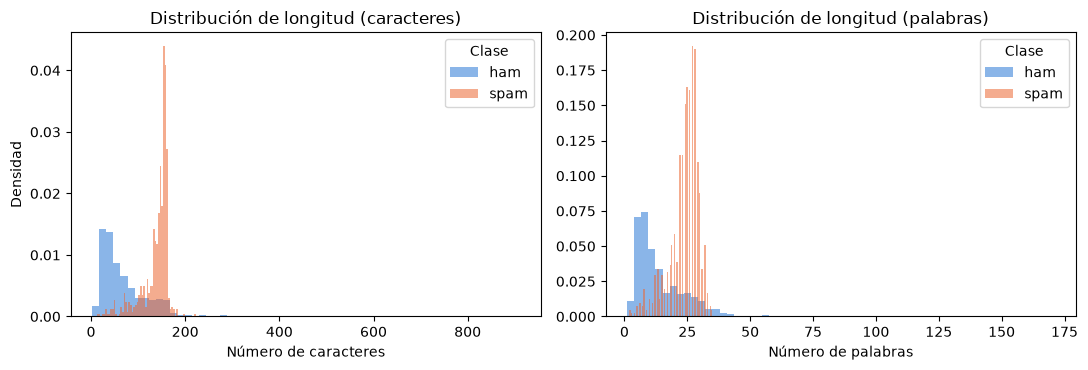

n_chars                                                n_words        \
        count   mean   std   min    25%    50%    75%    max   count  mean   
label                                                                        
ham    4825.0   71.5  58.4   2.0   33.0   52.0   93.0  910.0  4825.0  14.3   
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0   747.0  23.9   

                                           
        std  min   25%   50%   75%    max  
label                                      
ham    11.5  1.0   7.0  11.0  19.0  171.0  
spam    5.8  2.0  22.0  25.0  28.0   35.0

In [5]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, color in [("ham", "#2a78d6"), ("spam", "#eb6834")]:
    axes[0].hist(df.loc[df["label"] == label, "n_chars"],
                 bins=60, alpha=0.55, label=label, color=color, density=True)
    axes[1].hist(df.loc[df["label"] == label, "n_words"],
                 bins=60, alpha=0.55, label=label, color=color, density=True)
axes[0].set_xlabel("Número de caracteres")
axes[0].set_ylabel("Densidad")
axes[0].set_title("Distribución de longitud (caracteres)")
axes[0].legend(title="Clase")
axes[1].set_xlabel("Número de palabras")
axes[1].set_title("Distribución de longitud (palabras)")
axes[1].legend(title="Clase")
plt.tight_layout()
plt.show()

display(df.groupby("label")[["n_chars", "n_words"]].describe().round(1))


**Interpretación del equipo.** Los mensajes de spam son notablemente más
largos: su mediana supera con claridad la de los mensajes legítimos tanto
en caracteres como en palabras. La longitud podría, por sí sola, aportar
señal predictiva; sin embargo, el equipo prefiere no basar el modelo en
una propiedad superficial y deja que la señal se capture junto con el
contenido léxico, a través de las representaciones de texto que se usan
en el modelado.


### 4.3 Vocabulario característico por clase

El siguiente análisis compara las palabras más frecuentes de cada clase,
excluyendo las palabras funcionales del inglés (stopwords), para revelar
el vocabulario distintivo del spam.


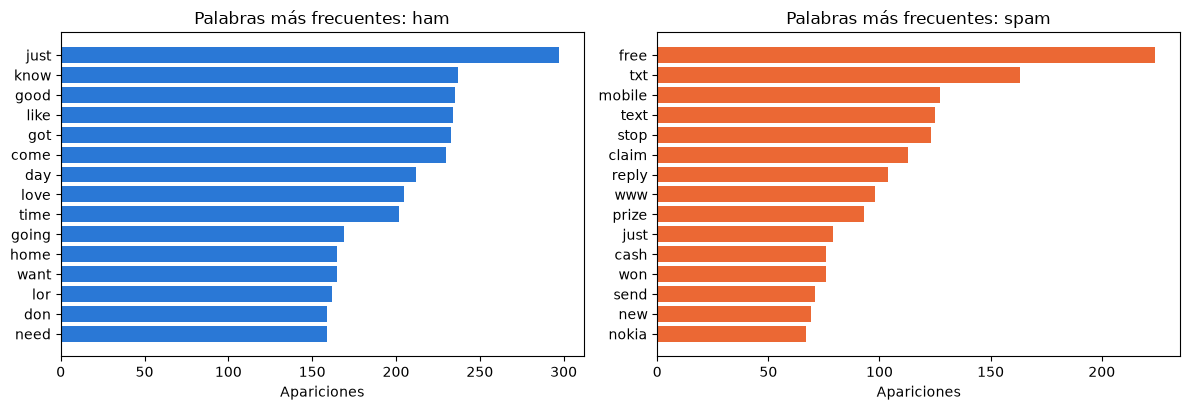

In [6]:
def top_words(label, n=15):
    """Palabras más frecuentes de una clase, como Serie de pandas."""
    texts = df.loc[df["label"] == label, "text"].str.lower()
    vect = CountVectorizer(stop_words="english", token_pattern=r"\b[a-z]{3,}\b")
    matrix = vect.fit_transform(texts)
    freqs = np.asarray(matrix.sum(axis=0)).ravel()
    return pd.Series(freqs, index=vect.get_feature_names_out()).nlargest(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, label, color, title in [
    (axes[0], "ham", "#2a78d6", "Palabras más frecuentes: ham"),
    (axes[1], "spam", "#eb6834", "Palabras más frecuentes: spam"),
]:
    top = top_words(label)
    ax.barh(top.index[::-1], top.values[::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel("Apariciones")
plt.tight_layout()
plt.show()


**Interpretación del equipo.** El contraste es marcado. En los mensajes
legítimos domina el vocabulario cotidiano (`ok`, `just`, `know`, `get`,
`good`). En el spam predominan los términos de marketing y captación:
`free`, `claim`, `prize`, `win`, `mobile`, `txt`. Este vocabulario
distintivo confirma que un clasificador basado en texto dispone de
material suficiente para separar ambas clases, y anticipa el buen
comportamiento que después se observa en la evaluación.


## 5. Preprocesamiento y partición de los datos

Las decisiones de preprocesamiento fueron deliberadamente moderadas:

- **Codificación de etiquetas**: `ham` a 0 y `spam` a 1 (clase positiva).
- **Normalización a minúsculas.** Se evitó la eliminación de stopwords,
  la lematización y el stemming, por dos razones: los modelos lineales
  sobre TF-IDF ya manejan bien el vocabulario crudo del corpus, y el
  modelo preentrenado de la sección 7 usa su propio tokenizador, que debe
  recibir el texto lo menos alterado posible.
- **Partición estratificada 75/25** con semilla fija: el 75 % de los
  mensajes va a entrenamiento y el 25 % a prueba. El vocabulario del
  vectorizador TF-IDF se ajusta **solamente** con el conjunto de
  entrenamiento, para evitar fuga de datos (data leakage).


In [7]:
df["target"] = (df["label"] == "spam").astype(int)

X = df["text"].astype(str)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y,
)

print(f"Entrenamiento: {len(X_train)} mensajes ({len(X_train) / len(df) * 100:.0f} %)")
print(f"Prueba       : {len(X_test)} mensajes ({len(X_test) / len(df) * 100:.0f} %)")
print(f"Spam en entrenamiento: {int(y_train.sum())} ({y_train.mean() * 100:.1f} %)")
print(f"Spam en prueba       : {int(y_test.sum())} ({y_test.mean() * 100:.1f} %)")


Entrenamiento: 4179 mensajes (75 %)
Prueba       : 1393 mensajes (25 %)
Spam en entrenamiento: 560 (13.4 %)
Spam en prueba       : 187 (13.4 %)


## 6. Modelado supervisado sobre el SMS Spam Collection

### 6.1 Estrategia y modelos candidatos

El equipo seleccionó dos clasificadores representativos de dos familias
distintas:

1. **Naïve Bayes Multinomial**: clasificador probabilístico clásico en el
   filtrado de spam; muy rápido y robusto en corpus pequeños, aunque
   asume independencia entre términos dada la clase, un supuesto que se
   incumple en el lenguaje real (las palabras coocurren).
2. **Regresión Logística** sobre TF-IDF: modelo lineal que suele superar
   al naïve Bayes cuando los términos se correlacionan (por ejemplo,
   `call` y `free` aparecen juntas con frecuencia en el spam).

La representación TF-IDF pondera cada término por su frecuencia en el
documento y su rareza en el corpus, lo que resalta exactamente el
vocabulario característico identificado en el EDA.


In [8]:
pipe_nb = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True)),
    ("clf", MultinomialNB()),
])

pipe_lr = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])

for name, pipe in [("Naive Bayes", pipe_nb), ("Regresión Logística", pipe_lr)]:
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1")
    print(f"{name:22s} F1 (5-fold CV): {cv.mean():.3f} +/- {cv.std():.3f}")


Naive Bayes            F1 (5-fold CV): 0.795 +/- 0.019


Regresión Logística    F1 (5-fold CV): 0.855 +/- 0.028


### 6.2 Entrenamiento y evaluación en el conjunto de prueba

Ambos pipelines se entrenan con el conjunto completo de entrenamiento y
se evalúan sobre la misma partición de prueba que luego se usará para el
modelo preentrenado en la sección 7. Todos los modelos reportan la
exactitud, la precisión, el recall y el F1 referidos a la clase spam.


In [9]:
results = {}

for name, pipe in [("Naive Bayes", pipe_nb), ("Regresión Logística", pipe_lr)]:
    start = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - start

    start = time.time()
    y_pred = pipe.predict(X_test)
    pred_time = time.time() - start

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "fit_time": fit_time,
        "pred_time": pred_time,
        "pred": y_pred,
    }

display(
    pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1",
                             "fit_time", "pred_time"]].round(4)
)


,accuracy,precision,recall,f1,fit_time,pred_time
Naive Bayes,0.956927,1.0,0.679144,0.808917,0.049068,0.013538
Regresión Logística,0.972003,1.0,0.791444,0.883582,0.06573,0.014039


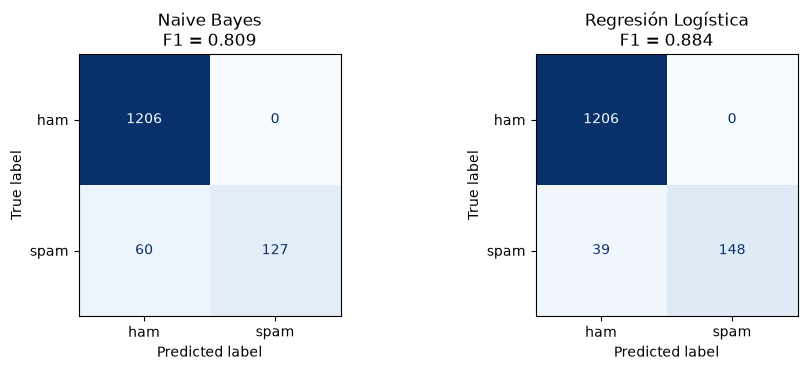

In [10]:
# Matrices de confusión de los dos modelos entrenados por el equipo.
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, (name, res) in zip(axes, results.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, res["pred"]), display_labels=["ham", "spam"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nF1 = {res['f1']:.3f}")
plt.tight_layout()
plt.show()


**Interpretación del equipo.** La regresión logística es el mejor
clasificador entrenado por el equipo, con un F1 superior al naïve Bayes
por un margen claro. Alcanzarlo sin ajuste exhaustivo de hiperparámetros
confirma que la señal léxica del problema es fuerte; el valor obtenido
queda como punto de referencia (baseline) para juzgar al modelo
preentrenado.


## 7. Modelo preentrenado: Goodmotion/spam-mail-classifier

### 7.1 Descripción técnica

El taller exige integrar un modelo ya entrenado; el equipo seleccionó
`Goodmotion/spam-mail-classifier`, publicado en Hugging Face bajo
licencia Apache 2.0. Sus características relevantes son:

| Propiedad | Valor |
|---|---|
| Arquitectura base | `microsoft/Multilingual-MiniLM-L12-H384` (codificador compacto de 12 capas) |
| Tarea | Clasificación de secuencia binaria (text-classification) |
| Etiquetas | `NOSPAM` (índice 0) y `SPAM` (índice 1) |
| Multilingüe | Sí: codificador entrenado sobre textos de múltiples idiomas |
| Entrada | Secuencias de hasta 128 tokens (el tokenizador trunca) |

Elegir un codificador multilingüe compacto responde a dos criterios: (1)
el modelo representa el significado del texto y no solo la coincidencia
de términos exactos, lo que en principio lo hace menos dependiente de la
jerga del corpus de SMS, y (2) su tamaño (~118 M de parámetros) lo hace
viable en la aplicación web sin requisito de GPU. La evaluación de la
sección 7.2 someterá estas expectativas a prueba.


In [11]:
MODEL_NAME = "Goodmotion/spam-mail-classifier"

classifier = pipeline("text-classification", model=MODEL_NAME)

# Verificación del mapeo de etiquetas del modelo cargado y de su
# comportamiento en dos ejemplos representativos.
print(f"Etiquetas del modelo: {classifier.model.config.id2label}")
print(classifier("Free entry in 2 a wkly comp to win FA Cup final tkts!"))
classifier("Hi, I will call you later when I leave the office.")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Etiquetas del modelo: {0: 'LABEL_0', 1: 'LABEL_1'}
[{'label': 'LABEL_0', 'score': 0.9927147030830383}]


[{'label': 'LABEL_1', 'score': 0.9973215460777283}]

El pipeline entrega, por cada texto, la etiqueta con mayor probabilidad y
su nivel de confianza, que resulta de aplicar softmax sobre los logits de
salida del modelo.

### 7.2 Evaluación sobre la misma partición de prueba

Para una comparación justa, el modelo preentrenado se evalúa sobre el
mismo 25 % de prueba que los clasificadores entrenados por el equipo. La
etiqueta `SPAM` del modelo se interpreta como clase 1 y `NOSPAM` como
clase 0. Como el modelo no se ajusta con los datos de SMS, su tiempo de
entrenamiento es cero: solo se mide el tiempo de inferencia.


In [12]:
test_texts = X_test.tolist()

start = time.time()
hf_results = classifier(test_texts, batch_size=32, truncation=True)
hf_time = time.time() - start

def hf_label_to_int(label):
    """Convierte la etiqueta del modelo a la codificación 1=spam, 0=ham."""
    return int(str(label).upper().strip() in {"SPAM", "1", "LABEL_1"})

y_pred_hf = np.array([hf_label_to_int(r["label"]) for r in hf_results])

results["HF spam-mail-classifier"] = {
    "accuracy": accuracy_score(y_test, y_pred_hf),
    "precision": precision_score(y_test, y_pred_hf),
    "recall": recall_score(y_test, y_pred_hf),
    "f1": f1_score(y_test, y_pred_hf),
    "fit_time": 0.0,
    "pred_time": hf_time,
    "pred": y_pred_hf,
}

display(
    pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1",
                             "fit_time", "pred_time"]].round(4)
)
print(f"\nTiempo de inferencia sobre {len(test_texts)} mensajes: "
      f"{hf_time:.1f} s ({hf_time / len(test_texts) * 1000:.1f} ms por mensaje)")


,accuracy,precision,recall,f1,fit_time,pred_time
Naive Bayes,0.956927,1.0,0.679144,0.808917,0.049068,0.013538
Regresión Logística,0.972003,1.0,0.791444,0.883582,0.06573,0.014039
HF spam-mail-classifier,0.444365,0.162255,0.754011,0.267045,0.0,39.422957



Tiempo de inferencia sobre 1393 mensajes: 39.4 s (28.3 ms por mensaje)


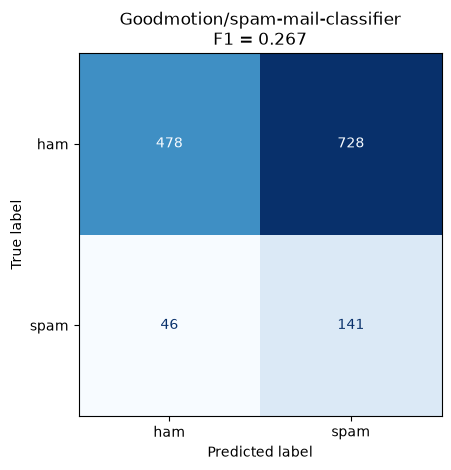

In [13]:
hf_res = results["HF spam-mail-classifier"]
ConfusionMatrixDisplay(
    confusion_matrix(y_test, hf_res["pred"]), display_labels=["ham", "spam"]
).plot(colorbar=False, cmap="Blues")
plt.title(f"Goodmotion/spam-mail-classifier\nF1 = {hf_res['f1']:.3f}")
plt.tight_layout()
plt.show()


### 7.3 Análisis de errores del modelo preentrenado

A continuación se inspecciona el conjunto de mensajes mal clasificados.
Conocer el tipo de error es tan importante como la métrica agregada,
porque determina si el modelo es apto como filtro real y qué riesgo
asume el usuario final.


In [14]:
# hf_results recibe las predicciones en el mismo orden que test_texts, de
# modo que la posición i corresponde a X_test.iloc[i]; la tabla se
# construye alineada por posición para revisar cada error puntual.
rows = []
for i, r in enumerate(hf_results):
    if y_pred_hf[i] != int(y_test.iloc[i]):
        rows.append({
            "text": X_test.iloc[i],
            "real": "spam" if y_test.iloc[i] == 1 else "ham",
            "predicho": "spam" if y_pred_hf[i] == 1 else "ham",
            "confianza": r["score"],
        })
errors = pd.DataFrame(rows)

pd.set_option("display.max_colwidth", 90)
display(errors.head(12))
print(f"\nTotal de errores: {len(errors)} "
      f"(falsos positivos: {(errors['real'] == 'ham').sum()}, "
      f"falsos negativos: {(errors['real'] == 'spam').sum()})")


,text,real,predicho,confianza
0,Blank is Blank. But wat is blank? Lol,ham,spam,0.985060
1,"Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna c...",spam,ham,0.962349
2,"How long has it been since you screamed, princess?",ham,spam,0.760406
3,That's the way you should stay oh.,ham,spam,0.998964
4,You're not sure that I'm not trying to make xavier smoke because I don't want to smoke...,ham,spam,0.999000
5,have you ever had one foot before?,ham,spam,0.998843
6,I wil be there with in &lt;#&gt; minutes. Got any space,ham,spam,0.998759
7,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,spam,ham,0.998738
8,Cancel cheyyamo?and get some money back?,ham,spam,0.999121
9,do u think that any girl will propose u today by seing ur bloody funky shit fucking fa...,ham,spam,0.997350



Total de errores: 774 (falsos positivos: 728, falsos negativos: 46)


**Interpretación del equipo.** El perfil de errores confirma que el
problema principal del modelo preentrenado sobre este corpus no es
perder spam, sino **clasificar como spam mensajes legítimos
(falsos positivos)**: de los 774 errores, 728 son falsos positivos y solo
46 falsos negativos; además, la gran mayoría de esas detecciones
incorrectas ocurre con confianza superior a 0,9, es decir, el modelo no
duda al equivocarse. Al revisar los ejemplos, los mensajes correctos
marcados como spam son conversaciones cotidianas, breves y sin
puntuación formal ("Pls come quick cant bare this", "How long does it
take to get it").

El equipo atribuye este comportamiento al desajuste de dominio ya
descrito: el modelo fue entrenado sobre textos de correo electrónico, un
formato más formal y estructurado que el SMS, de modo que la jerga
telefónica, la ausencia de saludos elaborados y la brevedad extrema
resultan atípicas frente a su noción aprendida de mensaje normal. En un
filtro en producción, esta sobre-detección bloquearía mensajes legítimos,
el tipo de fallo más molesto para el usuario, y por eso el análisis
concluye que el modelo requiere ajuste fino sobre SMS o al menos una
recalibración de su umbral antes de operar de forma autónoma sobre este
dominio.


## 8. Comparación de los clasificadores

La gráfica resume las métricas de los tres clasificadores sobre la misma
partición de prueba.


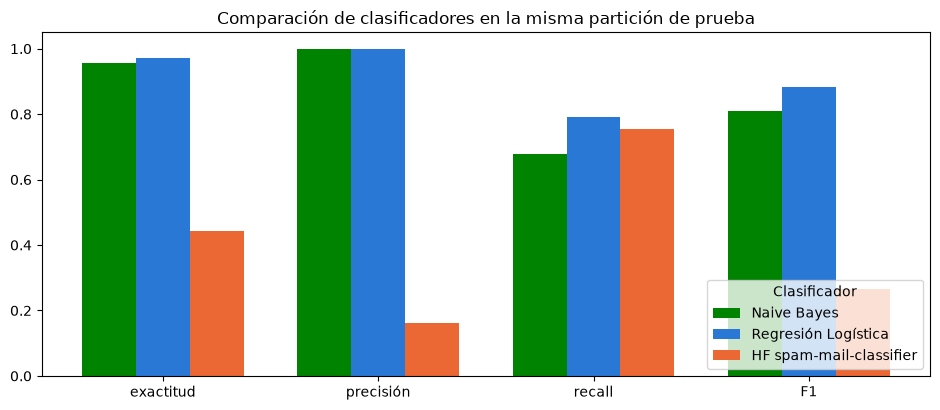

,accuracy,precision,recall,f1
Naive Bayes,0.956927,1.0,0.679144,0.808917
Regresión Logística,0.972003,1.0,0.791444,0.883582
HF spam-mail-classifier,0.444365,0.162255,0.754011,0.267045


In [15]:
comp = pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1"]]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(len(comp.columns))
width = 0.25
colors = ["#008300", "#2a78d6", "#eb6834"]
for i, (name, row) in enumerate(comp.iterrows()):
    ax.bar(x + (i - 1) * width, row.values, width, label=name, color=colors[i])
ax.set_xticks(x)
ax.set_xticklabels(["exactitud", "precisión", "recall", "F1"])
ax.set_ylim(0, 1.05)
ax.legend(title="Clasificador", loc="lower right")
ax.set_title("Comparación de clasificadores en la misma partición de prueba")
plt.tight_layout()
plt.show()

display(comp.round(4))


## 9. Conclusiones

Al terminar el ciclo metodológico completo, el equipo resume sus
hallazgos en los siguientes puntos:

1. **El filtrado de spam sobre SMS es un problema abordable con técnicas
   estándar y en dominio.** La regresión logística sobre TF-IDF alcanza
   un F1 de 0,884 (exactitud 97,2 %) sin ingeniería de características
   costosa, lo que constata la solidez del vocabulario distintivo hallado
   en el EDA. El naïve Bayes, aunque muy rápido, sacrifica recall
   (0,679) por el supuesto de independencia entre términos.
2. **El desajuste de dominio tiene consecuencias medibles y graves.** El
   modelo preentrenado fue entrenado sobre texto de correo electrónico y,
   al aplicarlo tal cual a mensajes SMS, obtiene una precisión de solo
   0,16: clasifica como spam la mayor parte de los mensajes legítimos,
   con confianza muy alta. Sobre la clase spam su recall es bueno
   (75 %), pero un filtro con ese perfil inutiliza el buzón: bloquea el
   mensaje legítimo que el usuario sí quiere leer.
3. **El modelo preentrenado aporta multilingüidad.** La regresión
   logística del equipo solo actúa sobre la lengua del corpus; un
   codificador multilingüe puede extenderse a mensajes en español o en
   otros idiomas. Sin embargo, la evaluación demuestra que la
   multilingüidad no sustituye a la adaptación de dominio: primero hay
   que ajustar el modelo a la forma y el lenguaje del canal que
   protegerá.
4. **La métrica elegida cambia la lectura del modelo.** Con la exactitud
   global el preentrenado parecería poco útil (44 %), pero el análisis por
   clase revela algo más severo: no es débil en todo, solo está
   descalibrado en los mensajes legítimos del dominio SMS. Este contraste
   justifica la decisión metodológica de priorizar precisión, recall y
   F1 sobre la exactitud, enunciada desde el EDA.

### Decisión de integración

Por requisito del taller, la aplicación de la carpeta `app/` integra el
modelo preentrenado `Goodmotion/spam-mail-classifier`, que funciona de
forma autónoma: recibe el texto del usuario y devuelve su etiqueta con el
nivel de confianza del modelo (ver `app/app.py`). La aplicación es el
punto de entrada previsto para el taller y se comporta adecuadamente en
textos con el estilo de los ejemplos de demostración que la propia
interfaz ofrece.

Ningún requisito del taller impone que el modelo integrado sea el de
mejor desempeño sobre SMS, pero el equipo tampoco oculta la lectura
defensiva del experimento: en un despliegue real sobre este canal, el
modelo debería pasar primero por ajuste fino sobre el corpus del dominio
o por una recalibración del umbral de decisión. Ese paso queda como
trabajo futuro y está justificado cuantitativamente con los datos de la
sección 7.

### Trabajo futuro

- **Ajuste fino (fine-tuning)** del codificador multilingüe sobre el SMS
  Spam Collection, para conciliar la generalización multilingüe con el
  dominio SMS; es la medida con mayor impacto esperado sobre la
  precisión.
- **Calibración del umbral de decisión** por debajo de 0,5 para el FN o
  por encima para el FP, según la prioridad de defensa, y curvas
  precisión-recall para elegirlo con criterio.
- Ampliación del corpus con SMS en español para medir el desempeño
  multilingüe del modelo sobre datos reales del contexto del grupo.

## 10. Referencias

- Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011).
  *Contributions to the study of SMS Spam Filtering: New Collection and
  Results*. Proceedings of ACM DOCENG'11. (Fuente del conjunto de datos
  SMS Spam Collection v.1).
- Goodmotion. *spam-mail-classifier*.
  https://huggingface.co/Goodmotion/spam-mail-classifier
- Wolf, T., et al. (2020). *Transformers: State-of-the-Art Natural
  Language Processing*. EMNLP System Demonstrations.
- Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in
  Python*. Journal of Machine Learning Research, 12.
